In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_palette("viridis")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Cleaned Dataset

df = pd.read_csv("../dataset/online_retail_II_cleaned.csv")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Cleaned Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()


Cleaned Dataset Loaded Successfully!
Dataset Shape: (1027017, 11)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancelled,Is_Return,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.0


In [3]:

# Separate Normal Sales Transactions

sales_df = df[
    (~df["Is_Cancelled"]) &
    (~df["Is_Return"]) &
    (df["Quantity"] > 0)
].copy()

# Separate Returned Transactions
returns_df = df[df["Is_Return"]].copy()

print("Normal Sales Records:", len(sales_df))
print("Returned Records:", len(returns_df))

print("Normal Sales Revenue:",
      round(sales_df["Sales"].sum(), 2))


Normal Sales Records: 1007913
Returned Records: 19103
Normal Sales Revenue: 20476260.45


In [4]:

# Extract Date Information

sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["Month_Name"] = sales_df["InvoiceDate"].dt.month_name()
sales_df["Day"] = sales_df["InvoiceDate"].dt.day
sales_df["Day_Name"] = sales_df["InvoiceDate"].dt.day_name()
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

print("Date Features Created Successfully!")

sales_df.head()


Date Features Created Successfully!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancelled,Is_Return,Sales,Year,Month,Month_Name,Day,Day_Name,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.4,2009,12,December,1,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0,2009,12,December,1,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0,2009,12,December,1,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.8,2009,12,December,1,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.0,2009,12,December,1,Tuesday,7


Month_Name
January      1340966.722
February     1074050.286
March        1547130.521
April        1215843.743
May          1427002.110
June         1510084.320
July         1366886.391
August       1453093.290
September    1978132.183
October      2313165.950
November     2968159.922
December     2281745.010
Name: Sales, dtype: float64


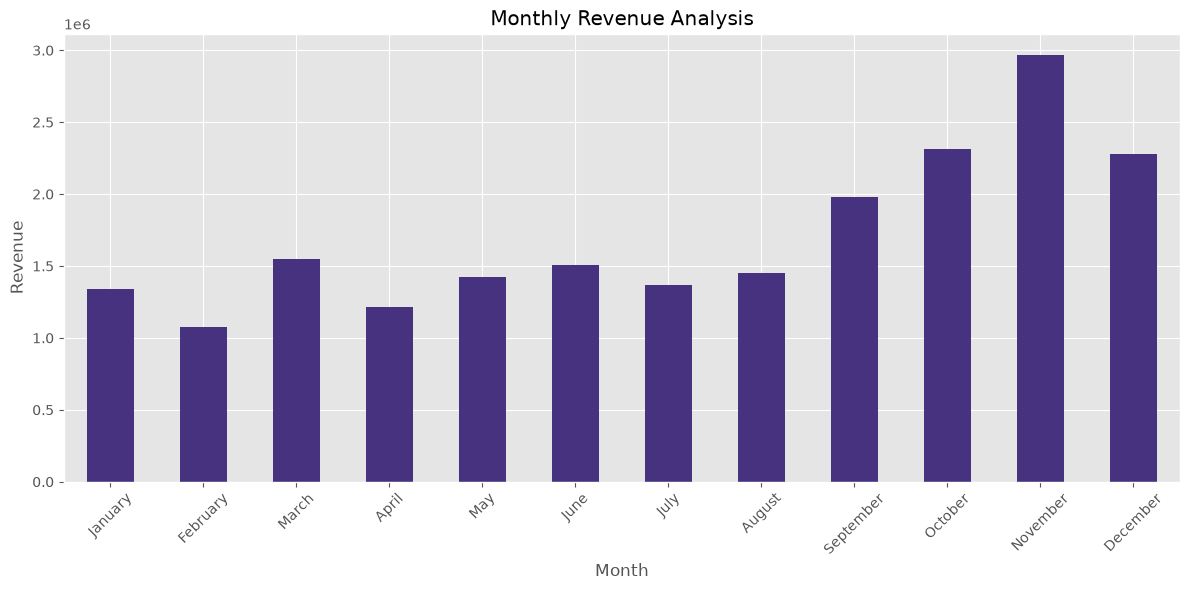

In [5]:

# Monthly Revenue Analysis

monthly_sales = (
    sales_df.groupby("Month_Name")["Sales"]
    .sum()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ])
)

print(monthly_sales)

plt.figure(figsize=(12, 6))
monthly_sales.plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Country
United Kingdom    1.741020e+07
EIRE              6.587673e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.504561e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.006856e+05
Sweden            9.186982e+04
Denmark           6.858069e+04
Name: Sales, dtype: float64


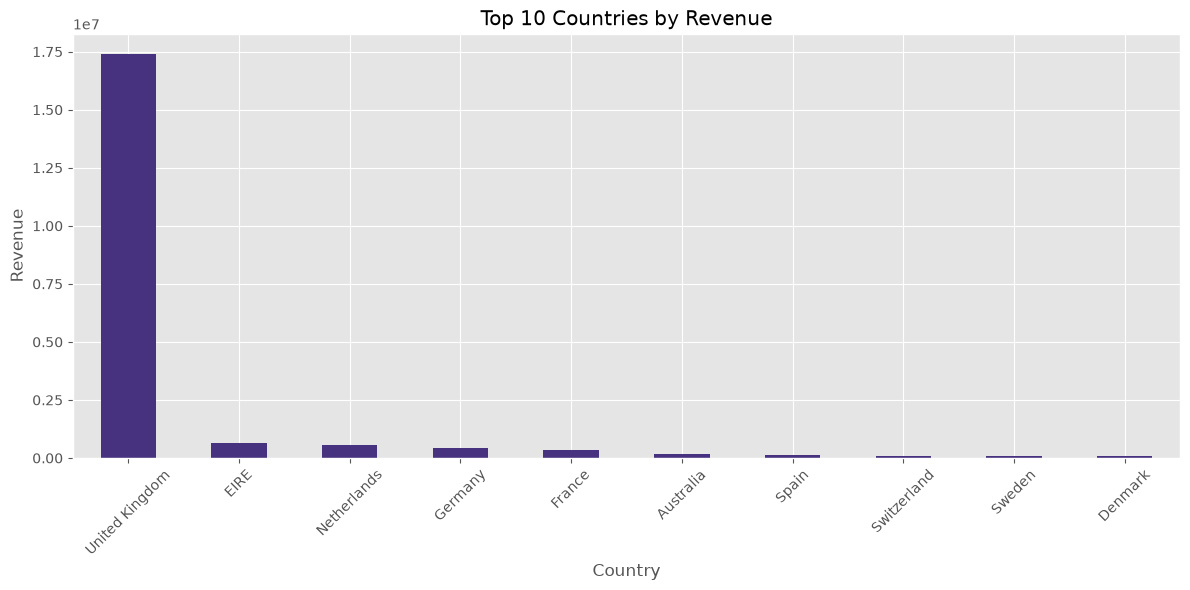

In [6]:

# Top 10 Countries by Revenue

country_sales = (
    sales_df.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

plt.figure(figsize=(12, 6))
country_sales.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Description
Manual                                339241.29
REGENCY CAKESTAND 3 TIER              330590.32
DOTCOM POSTAGE                        309854.11
WHITE HANGING HEART T-LIGHT HOLDER    260990.22
PAPER CRAFT , LITTLE BIRDIE           168469.60
PARTY BUNTING                         148318.28
JUMBO BAG RED RETROSPOT               148073.47
ASSORTED COLOUR BIRD ORNAMENT         129324.49
POSTAGE                               125682.42
PAPER CHAIN KIT 50'S CHRISTMAS        117760.29
Name: Sales, dtype: float64


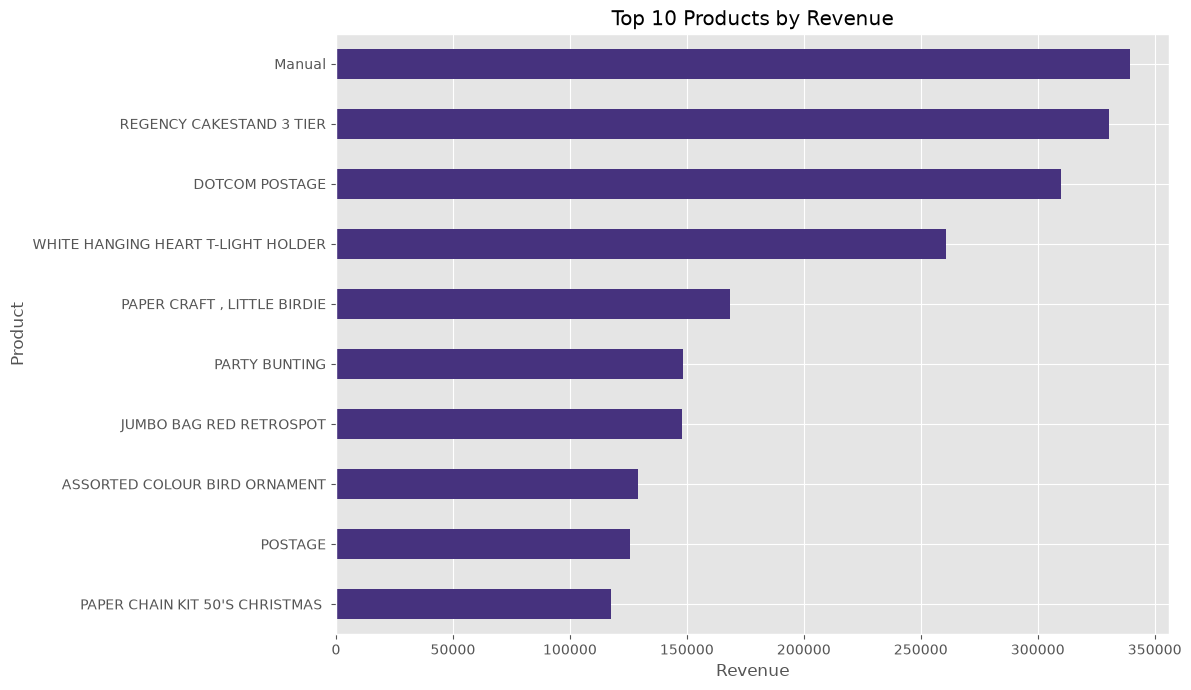

In [7]:

# Top 10 Products by Revenue

top_products = (
    sales_df.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

plt.figure(figsize=(12, 7))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Customer ID
18102.0    580987.04
14646.0    528602.52
14156.0    313437.62
14911.0    291420.81
17450.0    244784.25
13694.0    195640.69
17511.0    172132.87
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: Sales, dtype: float64


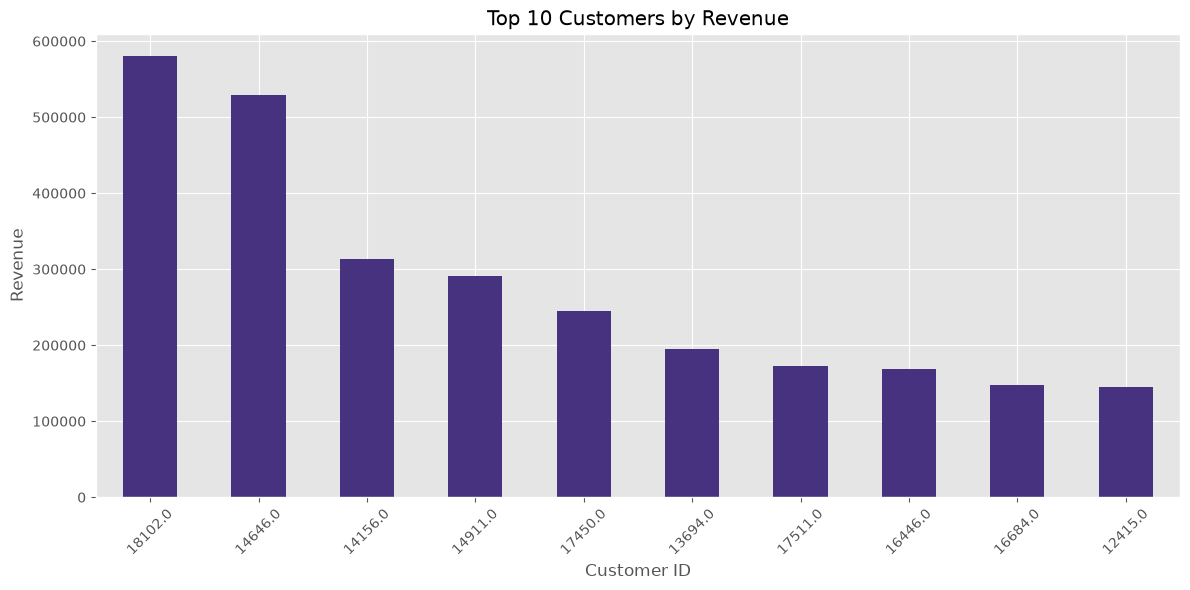

In [8]:

# Top 10 Customers by Revenue

customer_sales = (
    sales_df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(customer_sales)

plt.figure(figsize=(12, 6))
customer_sales.plot(kind="bar")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Day_Name
Monday       3581594.176
Tuesday      4078149.962
Wednesday    3488444.333
Thursday     4195212.762
Friday       3323908.883
Saturday        9803.050
Sunday       1799147.282
Name: Sales, dtype: float64


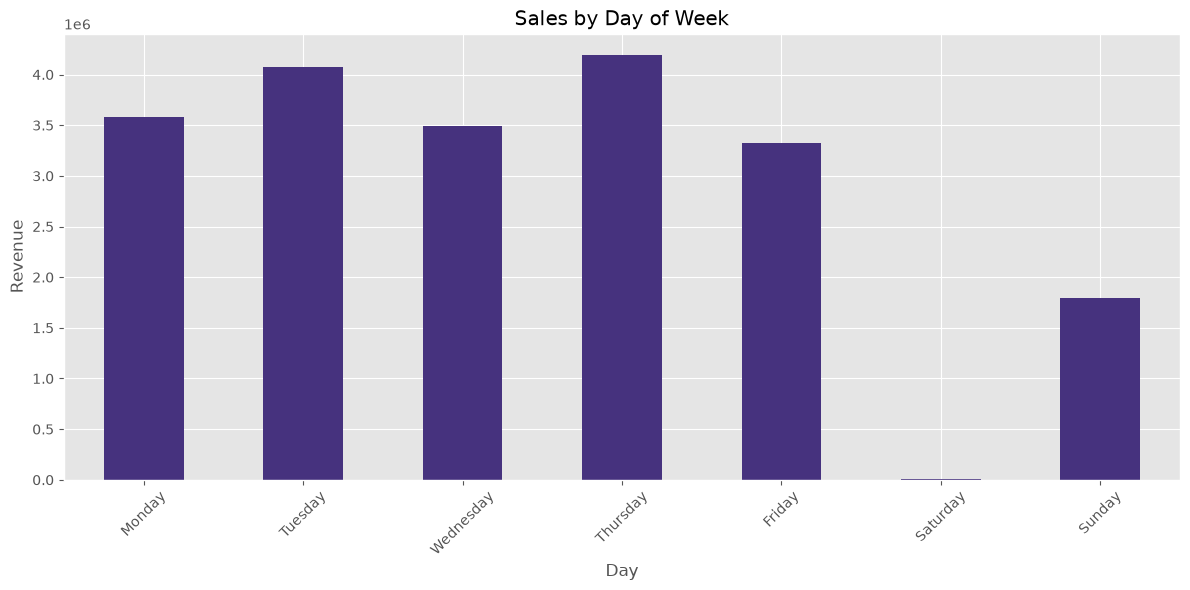

In [9]:

# Sales by Day of Week

day_sales = (
    sales_df.groupby("Day_Name")["Sales"]
    .sum()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

print(day_sales)

plt.figure(figsize=(12, 6))
day_sales.plot(kind="bar")

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Hour
6           4.250
7       75765.570
8      528185.570
9     1769631.031
10    2581131.333
11    2535325.463
12    2850377.671
13    2548467.544
14    2321684.731
15    2394943.792
16    1570143.801
17     861460.132
18     273405.020
19     126830.350
20      38904.190
Name: Sales, dtype: float64


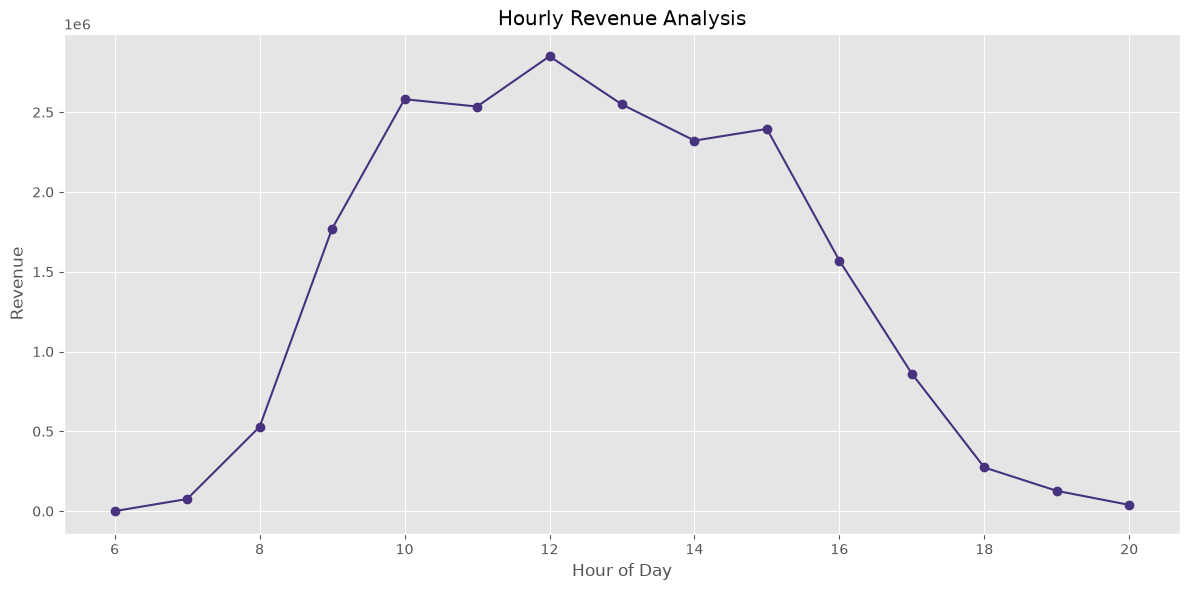

In [10]:

# Hourly Sales Analysis

hourly_sales = sales_df.groupby("Hour")["Sales"].sum()

print(hourly_sales)

plt.figure(figsize=(12, 6))
hourly_sales.plot(kind="line", marker="o")

plt.title("Hourly Revenue Analysis")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()


In [11]:

# Returns Analysis

total_returns = len(returns_df)
total_return_value = abs(returns_df["Sales"].sum())

total_sales = sales_df["Sales"].sum()

print("Total Returned Records:", total_returns)
print("Total Return Value:", round(total_return_value, 2))
print("Total Normal Sales:", round(total_sales, 2))


Total Returned Records: 19103
Total Return Value: 1462424.18
Total Normal Sales: 20476260.45


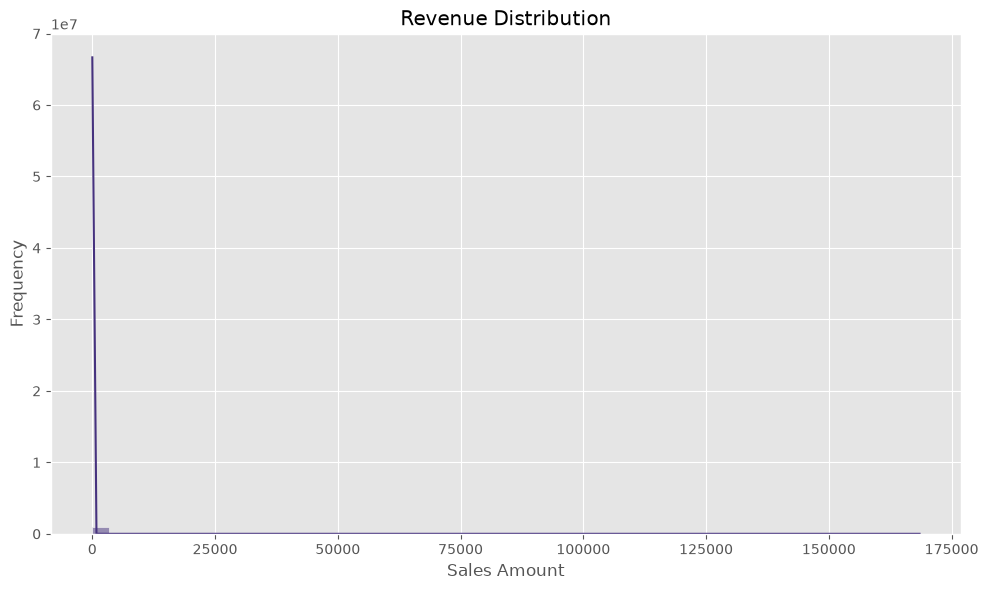

In [12]:

# Revenue Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    sales_df["Sales"],
    bins=50,
    kde=True
)

plt.title("Revenue Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [13]:

# Final Exploratory Data Analysis Summary

print("=" * 60)
print("CUSTOMER SHOPPING BEHAVIOR ANALYTICS")
print("EXPLORATORY DATA ANALYSIS REPORT")
print("=" * 60)

print("Total Sales Transactions:", len(sales_df))

print("Total Revenue:",
      round(sales_df["Sales"].sum(), 2))

print("Total Customers:",
      sales_df["Customer ID"].nunique())

print("Total Products:",
      sales_df["StockCode"].nunique())

print("Total Countries:",
      sales_df["Country"].nunique())

print("Total Return Records:", len(returns_df))

print("\nTop Selling Country:")
print(country_sales.index[0])

print("\nBest Revenue Generating Product:")
print(top_products.index[0])

print("\nHighest Revenue Generating Customer:")
print(customer_sales.index[0])

print("\nEDA Completed Successfully!")

print("=" * 60)


CUSTOMER SHOPPING BEHAVIOR ANALYTICS
EXPLORATORY DATA ANALYSIS REPORT
Total Sales Transactions: 1007913
Total Revenue: 20476260.45
Total Customers: 5878
Total Products: 4917
Total Countries: 43
Total Return Records: 19103

Top Selling Country:
United Kingdom

Best Revenue Generating Product:
Manual

Highest Revenue Generating Customer:
18102.0

EDA Completed Successfully!
